SESSÃO 07 — Construção de janelas temporais e preparação dos atributos para classificação supervisionada.

In [5]:

# SESSAO 07 - TAREFA 01
# Construir janelas temporais de uma instancia real

import io
import requests
import pandas as pd

arquivo = "WELL-00002_20131104004101.parquet"

url = (
    "https://raw.githubusercontent.com/petrobras/3W/"
    f"main/dataset/2/{arquivo}"
)

resposta = requests.get(url, timeout=60)
resposta.raise_for_status()

df = pd.read_parquet(io.BytesIO(resposta.content))

# Sensores selecionados para este exemplo
sensores = ["P-TPT", "T-TPT", "P-ANULAR"]

# Configuracao inicial das janelas
tamanho = 100
passo = 50

janelas = []
descartadas = 0

for inicio in range(0, len(df) - tamanho + 1, passo):

    trecho = df.iloc[inicio:inicio + tamanho]

    # Excluir janelas com sensores ausentes
    if trecho[sensores].isna().any().any():
        descartadas += 1
        continue

    # Excluir janelas com rotulos ausentes ou diferentes
    if (
        trecho["class"].isna().any()
        or trecho["class"].nunique() != 1
    ):
        descartadas += 1
        continue

    janelas.append({
        "Arquivo": arquivo,
        "Inicio": inicio,
        "Fim": inicio + tamanho - 1,
        "Rotulo": int(trecho["class"].iloc[0])
    })

tabela_janelas = pd.DataFrame(janelas)

print("TOTAL DE REGISTROS:", len(df))
print("JANELAS VALIDAS:", len(tabela_janelas))
print("JANELAS DESCARTADAS:", descartadas)

print("\nPRIMEIRAS JANELAS:")
display(tabela_janelas.head())

print("\nDISTRIBUICAO DOS ROTULOS:")
display(tabela_janelas["Rotulo"].value_counts().sort_index())

tabela_janelas.to_csv(
    "07_Janelas_Exemplo_V3.csv",
    index=False
)

print("\nTAREFA 01 EXECUTADA")


TOTAL DE REGISTROS: 12721
JANELAS VALIDAS: 177
JANELAS DESCARTADAS: 76

PRIMEIRAS JANELAS:


,Arquivo,Inicio,Fim,Rotulo
0,WELL-00002_20131104004101.parquet,3600,3699,0
1,WELL-00002_20131104004101.parquet,3650,3749,0
2,WELL-00002_20131104004101.parquet,3700,3799,0
3,WELL-00002_20131104004101.parquet,3750,3849,0
4,WELL-00002_20131104004101.parquet,3800,3899,0



DISTRIBUICAO DOS ROTULOS:


,count
Rotulo,
0,74
2,2
102,101



TAREFA 01 EXECUTADA


DIAGNOSTICO DAS JANELAS:


,Situacao,Quantidade
0,Rotulos ausentes,72
1,Validas,177
2,Mudanca de rotulo,4



ROTULOS NOS REGISTROS ORIGINAIS:


,Registros
class,
0,3755
2,217
102,5149
<NA>,3600


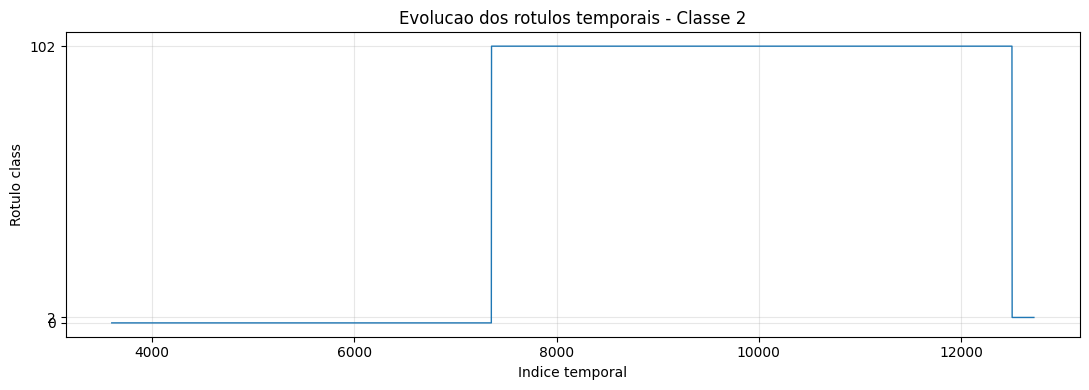


TAREFA 02 EXECUTADA


In [6]:

# SESSAO 07 - TAREFA 02
# Inspecao dos rotulos e janelas descartadas

import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

motivos = Counter()

for inicio in range(0, len(df) - tamanho + 1, passo):

    trecho = df.iloc[inicio:inicio + tamanho]

    if trecho[sensores].isna().any().any():
        motivos["Sensores ausentes"] += 1

    elif trecho["class"].isna().any():
        motivos["Rotulos ausentes"] += 1

    elif trecho["class"].nunique() != 1:
        motivos["Mudanca de rotulo"] += 1

    else:
        motivos["Validas"] += 1

print("DIAGNOSTICO DAS JANELAS:")
display(
    pd.DataFrame(
        motivos.items(),
        columns=["Situacao", "Quantidade"]
    )
)

print("\nROTULOS NOS REGISTROS ORIGINAIS:")
display(
    df["class"].value_counts(dropna=False)
    .sort_index()
    .to_frame("Registros")
)

# Visualizar a evolucao dos rotulos
plt.figure(figsize=(11, 4))

plt.plot(
    range(len(df)),
    df["class"],
    linewidth=1
)

plt.title("Evolucao dos rotulos temporais - Classe 2")
plt.xlabel("Indice temporal")
plt.ylabel("Rotulo class")
plt.yticks([0, 2, 102])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTAREFA 02 EXECUTADA")


In [7]:

# SESSAO 07 - TAREFA 03
# Extracao de 9 atributos por sensor e janela

import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis

resultados = []

for janela in tabela_janelas.itertuples(index=False):

    trecho = df.iloc[
        janela.Inicio:janela.Fim + 1
    ]

    linha = {
        "Arquivo": janela.Arquivo,
        "Inicio": janela.Inicio,
        "Fim": janela.Fim,
        "Rotulo": janela.Rotulo
    }

    for sensor in sensores:

        x = trecho[sensor].to_numpy(dtype=float)

        linha[f"{sensor}_media"] = np.mean(x)
        linha[f"{sensor}_desvio"] = np.std(x, ddof=1)
        linha[f"{sensor}_minimo"] = np.min(x)
        linha[f"{sensor}_q25"] = np.quantile(x, 0.25)
        linha[f"{sensor}_mediana"] = np.median(x)
        linha[f"{sensor}_q75"] = np.quantile(x, 0.75)
        linha[f"{sensor}_maximo"] = np.max(x)

        # Evitar estatisticas indefinidas
        # em sinais constantes
        if np.ptp(x) > 1e-9:
            linha[f"{sensor}_assimetria"] = skew(x)
            linha[f"{sensor}_curtose"] = kurtosis(x)
        else:
            linha[f"{sensor}_assimetria"] = np.nan
            linha[f"{sensor}_curtose"] = np.nan

    resultados.append(linha)

atributos_janelas = pd.DataFrame(resultados)

# Separar atributos das informacoes de controle
colunas_atributos = [
    c for c in atributos_janelas.columns
    if c not in ["Arquivo", "Inicio", "Fim", "Rotulo"]
]

print("JANELAS:", len(atributos_janelas))
print("ATRIBUTOS:", len(colunas_atributos))

print("\nPRIMEIRAS LINHAS:")
display(atributos_janelas.head())

print("\nVALORES AUSENTES NOS ATRIBUTOS:")
display(
    atributos_janelas[colunas_atributos]
    .isna().sum()
    .to_frame("Ausentes")
)

atributos_janelas.to_csv(
    "07_Atributos_Janelas_Exemplo_V3.csv",
    index=False
)

print("\nTAREFA 03 EXECUTADA")



JANELAS: 177
ATRIBUTOS: 27

PRIMEIRAS LINHAS:


,Arquivo,Inicio,Fim,Rotulo,P-TPT_media,P-TPT_desvio,P-TPT_minimo,P-TPT_q25,P-TPT_mediana,P-TPT_q75,...,T-TPT_curtose,P-ANULAR_media,P-ANULAR_desvio,P-ANULAR_minimo,P-ANULAR_q25,P-ANULAR_mediana,P-ANULAR_q75,P-ANULAR_maximo,P-ANULAR_assimetria,P-ANULAR_curtose
0,WELL-00002_20131104004101.parquet,3600,3699,0,18852350.0,0.0,18852350.0,18852350.0,18852350.0,18852350.0,...,-1.203087,17276330.0,0.0,17276330.0,17276330.0,17276330.0,17276330.0,17276330.0,NaN,NaN
1,WELL-00002_20131104004101.parquet,3650,3749,0,18852350.0,0.0,18852350.0,18852350.0,18852350.0,18852350.0,...,-1.196193,17276330.0,0.0,17276330.0,17276330.0,17276330.0,17276330.0,17276330.0,NaN,NaN
2,WELL-00002_20131104004101.parquet,3700,3799,0,18852350.0,0.0,18852350.0,18852350.0,18852350.0,18852350.0,...,-1.203139,17276330.0,0.0,17276330.0,17276330.0,17276330.0,17276330.0,17276330.0,NaN,NaN
3,WELL-00002_20131104004101.parquet,3750,3849,0,18852350.0,0.0,18852350.0,18852350.0,18852350.0,18852350.0,...,-1.201454,17276330.0,0.0,17276330.0,17276330.0,17276330.0,17276330.0,17276330.0,NaN,NaN
4,WELL-00002_20131104004101.parquet,3800,3899,0,18852350.0,0.0,18852350.0,18852350.0,18852350.0,18852350.0,...,-0.181077,17276330.0,0.0,17276330.0,17276330.0,17276330.0,17276330.0,17276330.0,NaN,NaN



VALORES AUSENTES NOS ATRIBUTOS:


,Ausentes
P-TPT_media,0
P-TPT_desvio,0
P-TPT_minimo,0
P-TPT_q25,0
P-TPT_mediana,0
P-TPT_q75,0
P-TPT_maximo,0
P-TPT_assimetria,72
P-TPT_curtose,72
T-TPT_media,0



TAREFA 03 EXECUTADA


In [8]:

# SESSAO 07 - TAREFA 04
# Diagnostico final dos atributos por rotulo

import pandas as pd

resumo = []

for rotulo, grupo in atributos_janelas.groupby("Rotulo"):

    for sensor in sensores:

        desvio = grupo[f"{sensor}_desvio"]

        resumo.append({
            "Rotulo": rotulo,
            "Sensor": sensor,
            "Janelas": len(grupo),
            "Janelas_constantes": int((desvio < 1e-9).sum()),
            "Assimetria_ausente": int(
                grupo[f"{sensor}_assimetria"].isna().sum()
            )
        })

diagnostico_final = pd.DataFrame(resumo)

print("DIAGNOSTICO POR ROTULO E SENSOR:")
display(diagnostico_final)

diagnostico_final.to_csv(
    "07_Diagnostico_Atributos_V3.csv",
    index=False
)

print("\nTAREFA 04 EXECUTADA")


DIAGNOSTICO POR ROTULO E SENSOR:


,Rotulo,Sensor,Janelas,Janelas_constantes,Assimetria_ausente
0,0,P-TPT,74,72,72
1,0,T-TPT,74,10,10
2,0,P-ANULAR,74,63,63
3,2,P-TPT,2,0,0
4,2,T-TPT,2,0,0
5,2,P-ANULAR,2,0,0
6,102,P-TPT,101,0,0
7,102,T-TPT,101,0,0
8,102,P-ANULAR,101,0,0



TAREFA 04 EXECUTADA
